# 01 · Análisis Exploratorio de Datos (EDA) — AdventureWorks · Módulo Sales

**Objetivo:** entender el comportamiento de ventas de AdventureWorks (2011‑2014) antes de segmentar clientes con K‑Means.

**Fuente:** base `AdventureWorks2022` (SQL Server), esquema `Sales`, extraída con `python -m src.extract` a `data/raw/*.parquet`.

| Tabla extraída | Contenido |
|---|---|
| `orders` | `Sales.SalesOrderHeader` + territorio + tipo de cliente (Individual / Store) |
| `order_details` | `Sales.SalesOrderDetail` + producto, subcategoría y categoría |
| `demographics` | `Sales.vPersonDemographics` de clientes individuales (sin datos personales identificables) |
| `sales_reasons` | Motivos de compra declarados por pedido |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from src.features import load_raw, build_customer_features
from src.viz import set_style, PALETTE, SEQ, MUTED

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 50)

## 1. Carga y estructura de los datos

In [2]:
orders, details, demo, reasons = load_raw()
for name, df in {"orders": orders, "order_details": details, "demographics": demo, "sales_reasons": reasons}.items():
    print(f"{name:15s} {df.shape[0]:>8,} filas × {df.shape[1]:>2} columnas")

orders            31,465 filas × 18 columnas
order_details    121,317 filas × 13 columnas
demographics      18,484 filas × 13 columnas
sales_reasons     27,647 filas ×  3 columnas


In [3]:
orders.head()

,SalesOrderID,OrderDate,DueDate,ShipDate,Status,OnlineOrderFlag,CustomerID,SalesPersonID,TerritoryID,Territory,Country,TerritoryGroup,SubTotal,TaxAmt,Freight,TotalDue,CustomerType,Channel
0,43659,2011-05-31,2011-06-12,2011-06-07,5,0,29825,279.00,5,Southeast,US,North America,"20,565.62","1,971.51",616.10,"23,153.23",Store,Vendedor
1,43660,2011-05-31,2011-06-12,2011-06-07,5,0,29672,279.00,5,Southeast,US,North America,"1,294.25",124.25,38.83,"1,457.33",Store,Vendedor
2,43661,2011-05-31,2011-06-12,2011-06-07,5,0,29734,282.00,6,Canada,CA,North America,"32,726.48","3,153.77",985.55,"36,865.80",Store,Vendedor
3,43662,2011-05-31,2011-06-12,2011-06-07,5,0,29994,282.00,6,Canada,CA,North America,"28,832.53","2,775.16",867.24,"32,474.93",Store,Vendedor
4,43663,2011-05-31,2011-06-12,2011-06-07,5,0,29565,276.00,4,Southwest,US,North America,419.46,40.27,12.58,472.31,Store,Vendedor


In [4]:
orders.dtypes.to_frame('tipo').T

,SalesOrderID,OrderDate,DueDate,ShipDate,Status,OnlineOrderFlag,CustomerID,SalesPersonID,TerritoryID,Territory,Country,TerritoryGroup,SubTotal,TaxAmt,Freight,TotalDue,CustomerType,Channel
tipo,int64,datetime64[us],datetime64[us],datetime64[us],int64,int64,int64,float64,int64,str,str,str,float64,float64,float64,float64,str,str


## 2. Calidad de datos

Revisamos valores nulos, duplicados, valores fuera de rango y consistencia contable.

In [5]:
def nulls(df):
    n = df.isna().sum()
    return pd.DataFrame({"nulos": n, "%": 100 * n / len(df)}).query("nulos > 0")

print("orders:"); display(nulls(orders))
print("order_details:"); display(nulls(details))
print("demographics:"); display(nulls(demo))

orders:


,nulos,%
SalesPersonID,27659,87.90


order_details:


,nulos,%


demographics:


,nulos,%


> **Lectura:** `SalesPersonID` es nulo en todos los pedidos **online** (no intervino un vendedor): es un nulo *estructural*, no un error.
> `ShipDate` puede ser nulo si el pedido aún no se despacha.

In [6]:
checks = pd.Series({
    "Pedidos duplicados": orders["SalesOrderID"].duplicated().sum(),
    "Líneas duplicadas": details["SalesOrderDetailID"].duplicated().sum(),
    "SubTotal <= 0": (orders["SubTotal"] <= 0).sum(),
    "Cantidad <= 0": (details["OrderQty"] <= 0).sum(),
    "Precio unitario <= 0": (details["UnitPrice"] <= 0).sum(),
    "TotalDue ≠ SubTotal+Tax+Freight": (~np.isclose(orders["TotalDue"], orders[["SubTotal","TaxAmt","Freight"]].sum(axis=1), atol=0.01)).sum(),
    "SubTotal ≠ Σ LineTotal": (~np.isclose(orders.set_index("SalesOrderID")["SubTotal"], details.groupby("SalesOrderID")["LineTotal"].sum(), atol=0.05)).sum(),
    "ShipDate < OrderDate": (orders["ShipDate"] < orders["OrderDate"]).sum(),
})
checks.to_frame("registros con problema")

,registros con problema
Pedidos duplicados,0
Líneas duplicadas,0
SubTotal <= 0,0
Cantidad <= 0,0
Precio unitario <= 0,0
TotalDue ≠ SubTotal+Tax+Freight,0
SubTotal ≠ Σ LineTotal,0
ShipDate < OrderDate,0


## 3. Estadística descriptiva

In [7]:
orders[["SubTotal", "TaxAmt", "Freight", "TotalDue"]].describe().T

,count,mean,std,min,25%,50%,75%,max
SubTotal,"31,465.00","3,491.07","11,093.45",1.37,56.97,782.99,"2,366.96","163,930.39"
TaxAmt,"31,465.00",323.76,"1,085.05",0.11,4.56,62.64,189.60,"17,948.52"
Freight,"31,465.00",101.17,339.08,0.03,1.42,19.57,59.25,"5,608.91"
TotalDue,"31,465.00","3,916.00","12,515.46",1.52,62.95,865.20,"2,615.49","187,487.83"


In [8]:
details[["OrderQty", "UnitPrice", "UnitPriceDiscount", "LineTotal"]].describe().T

,count,mean,std,min,25%,50%,75%,max
OrderQty,"121,317.00",2.27,2.49,1.00,1.00,1.00,3.00,44.00
UnitPrice,"121,317.00",465.09,751.89,1.33,21.49,49.99,602.35,"3,578.27"
UnitPriceDiscount,"121,317.00",0.00,0.02,0.00,0.00,0.00,0.00,0.40
LineTotal,"121,317.00",905.45,"1,693.42",1.37,24.99,134.98,"1,120.49","27,893.62"


In [9]:
kpi = pd.Series({
    "Periodo": f"{orders.OrderDate.min():%Y-%m-%d} → {orders.OrderDate.max():%Y-%m-%d}",
    "Pedidos": f"{len(orders):,}",
    "Clientes con compras": f"{orders.CustomerID.nunique():,}",
    "Productos vendidos (distintos)": f"{details.ProductID.nunique():,}",
    "Ventas netas (SubTotal)": f"${orders.SubTotal.sum():,.0f}",
    "Ticket promedio": f"${orders.SubTotal.mean():,.0f}",
    "% pedidos online": f"{orders.OnlineOrderFlag.mean():.1%}",
})
kpi.to_frame("valor")

,valor
Periodo,2011-05-31 → 2014-06-30
Pedidos,"31,465"
Clientes con compras,"19,119"
Productos vendidos (distintos),266
Ventas netas (SubTotal),"$109,846,381"
Ticket promedio,"$3,491"
% pedidos online,87.9%


## 4. Evolución temporal de las ventas

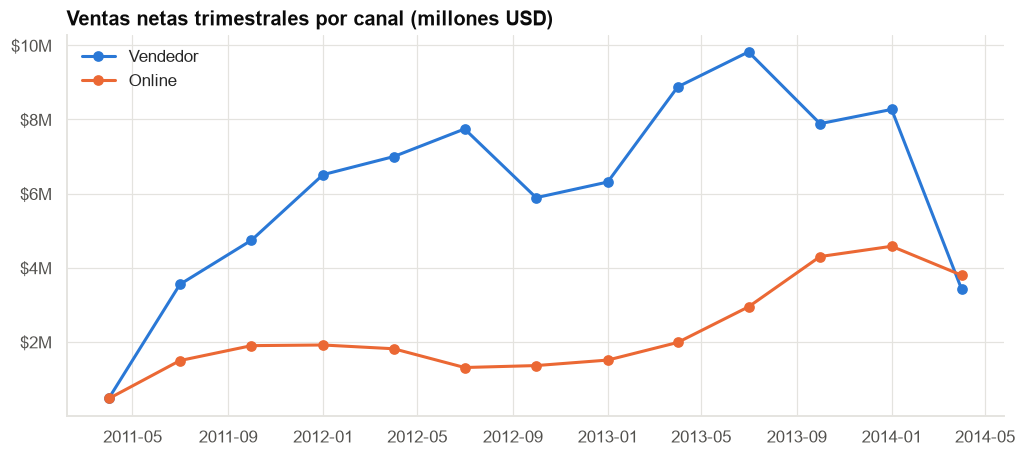

In [10]:
quarterly = (orders.set_index("OrderDate")
             .groupby([pd.Grouper(freq="QS"), "Channel"])["SubTotal"].sum()
             .unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, ch in enumerate(["Vendedor", "Online"]):
    ax.plot(quarterly.index, quarterly[ch] / 1e6, color=PALETTE[i], label=ch, marker="o", markersize=6)
ax.set_title("Ventas netas trimestrales por canal (millones USD)")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("$%.0fM"))
ax.set_xlabel(""); ax.legend(loc="upper left")
plt.show()

> Se agrega por **trimestre** porque los pedidos de las tiendas (canal *Vendedor*) se registran en bloque a fin de mes, lo que hace que la serie mensual salte entre $0 y $5 M. El primer trimestre (2011‑T2) solo tiene datos desde el 31 de mayo.

In [11]:
yearly = orders.assign(Year=orders.OrderDate.dt.year).pivot_table(
    index="Year", columns="CustomerType", values="SubTotal", aggfunc="sum")
yearly["Total"] = yearly.sum(axis=1)
yearly["Crec. %"] = yearly["Total"].pct_change() * 100
yearly

CustomerType,Individual,Store,Total,Crec. %
Year,,,,
2011,"3,863,120.21","8,778,552.00","12,641,672.21",NaN
2012,"6,390,599.95","27,133,701.38","33,524,301.33",165.19
2013,"10,732,127.33","32,890,351.72","43,622,479.05",30.12
2014,"8,372,829.73","11,685,099.08","20,057,928.81",-54.02


> **Nota:** 2011 (desde mayo) y 2014 (hasta junio) son años **parciales**; el crecimiento interanual solo es comparable entre 2012 y 2013.

### 4.1 Cambio estructural en el canal B2C (2013)

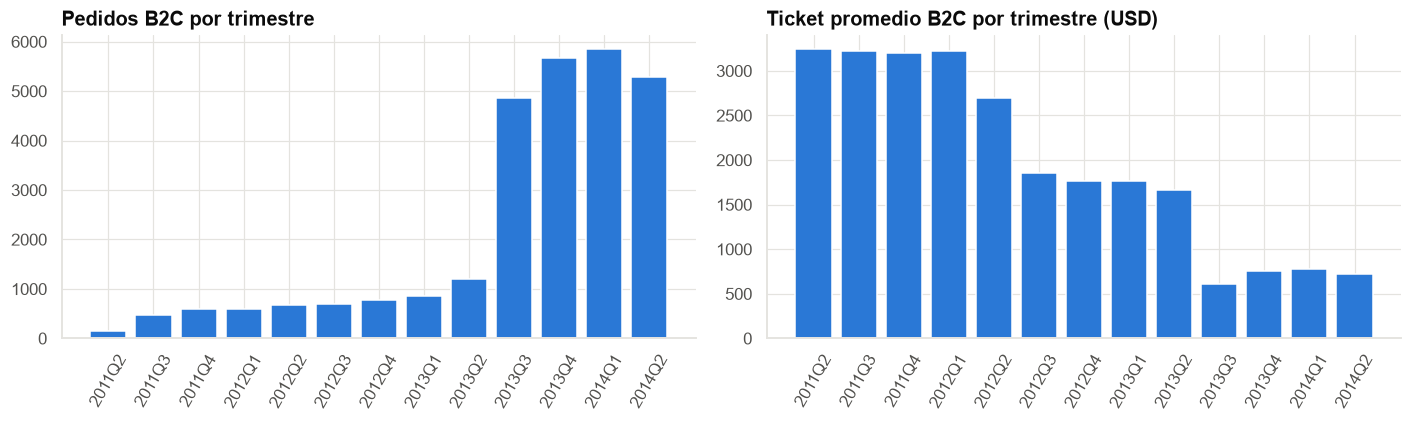

,Pedidos,Ticket
OrderDate,,
2011Q2,146,"3,242.38"
2011Q3,463,"3,225.62"
2011Q4,592,"3,203.16"
2012Q1,594,"3,221.74"
2012Q2,673,"2,692.23"
2012Q3,705,"1,853.07"
2012Q4,771,"1,762.12"
2013Q1,852,"1,768.64"
2013Q2,1192,"1,663.37"


In [12]:
ind = orders[orders.CustomerType == "Individual"]
q = ind.groupby(ind.OrderDate.dt.to_period("Q")).agg(Pedidos=("SalesOrderID", "count"), Ticket=("SubTotal", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(q.index.astype(str), q["Pedidos"], color=PALETTE[0]); axes[0].set_title("Pedidos B2C por trimestre")
axes[1].bar(q.index.astype(str), q["Ticket"], color=PALETTE[0]); axes[1].set_title("Ticket promedio B2C por trimestre (USD)")
for ax in axes: ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
q

> **Hallazgo:** desde **2013‑T3** los pedidos de clientes individuales se multiplican ×4 mientras el ticket promedio cae de ~$1.660 a ~$600:
> AdventureWorks empezó a vender **accesorios y ropa** online a personas. Esto crea una masa de clientes nuevos de bajo valor que el clustering debe detectar.

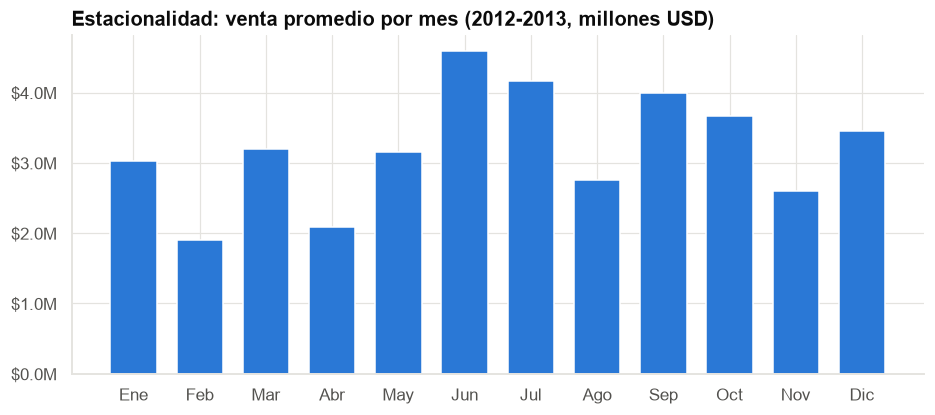

In [13]:
orders["Month"] = orders.OrderDate.dt.month
season = orders[orders.OrderDate.dt.year.isin([2012, 2013])].groupby("Month")["SubTotal"].sum() / 2
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(season.index, season / 1e6, color=PALETTE[0], width=0.7)
ax.set_xticks(range(1, 13), ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax.set_title("Estacionalidad: venta promedio por mes (2012-2013, millones USD)")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("$%.1fM"))
plt.show()

## 5. Clientes individuales (B2C) vs. tiendas (B2B)

In [14]:
seg = orders.groupby("CustomerType").agg(
    Pedidos=("SalesOrderID", "count"),
    Clientes=("CustomerID", "nunique"),
    Ventas=("SubTotal", "sum"),
    Ticket_promedio=("SubTotal", "mean"),
)
seg["% ventas"] = 100 * seg["Ventas"] / seg["Ventas"].sum()
seg["Pedidos por cliente"] = seg["Pedidos"] / seg["Clientes"]
seg

,Pedidos,Clientes,Ventas,Ticket_promedio,% ventas,Pedidos por cliente
CustomerType,,,,,,
Individual,27659,18484,"29,358,677.22","1,061.45",26.73,1.50
Store,3806,635,"80,487,704.18","21,147.58",73.27,5.99


> **Hallazgo clave:** las ~635 tiendas generan cerca del **73 % de las ventas** con tickets ~20× mayores que los clientes individuales.
> Mezclar ambos grupos en un mismo K‑Means haría que el algoritmo solo separe "tiendas vs. personas".
> Por eso el clustering (notebook 02) se hace **solo sobre clientes individuales**.

## 6. Ventas por territorio

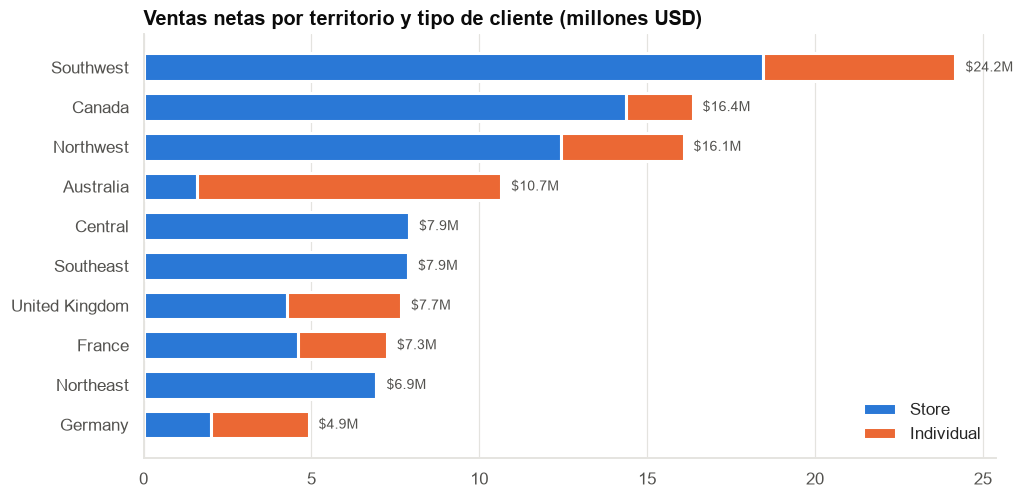

In [15]:
terr = orders.groupby(["Territory", "CustomerType"])["SubTotal"].sum().unstack(fill_value=0)
terr = terr.loc[terr.sum(axis=1).sort_values().index] / 1e6
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(terr))
for i, col in enumerate(["Store", "Individual"]):
    ax.barh(terr.index, terr[col], left=left, color=PALETTE[i], label=col, height=0.7,
            edgecolor="white", linewidth=2)
    left += terr[col].values
for y, v in enumerate(left):
    ax.text(v + 0.3, y, f"${v:,.1f}M", va="center", color=MUTED, fontsize=9)
ax.set_title("Ventas netas por territorio y tipo de cliente (millones USD)")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plt.show()

## 7. Productos y categorías

In [16]:
cat = details.groupby("Category").agg(Ventas=("LineTotal", "sum"), Unidades=("OrderQty", "sum"),
                                       Lineas=("SalesOrderDetailID", "count"))
cat["% ventas"] = 100 * cat["Ventas"] / cat["Ventas"].sum()
cat["% unidades"] = 100 * cat["Unidades"] / cat["Unidades"].sum()
cat.sort_values("Ventas", ascending=False)

,Ventas,Unidades,Lineas,% ventas,% unidades
Category,,,,,
Bikes,"94,651,172.70",90268,40031,86.17,32.83
Components,"11,802,593.29",49044,18698,10.74,17.84
Clothing,"2,120,542.52",73670,21394,1.93,26.80
Accessories,"1,272,072.88",61932,41194,1.16,22.53


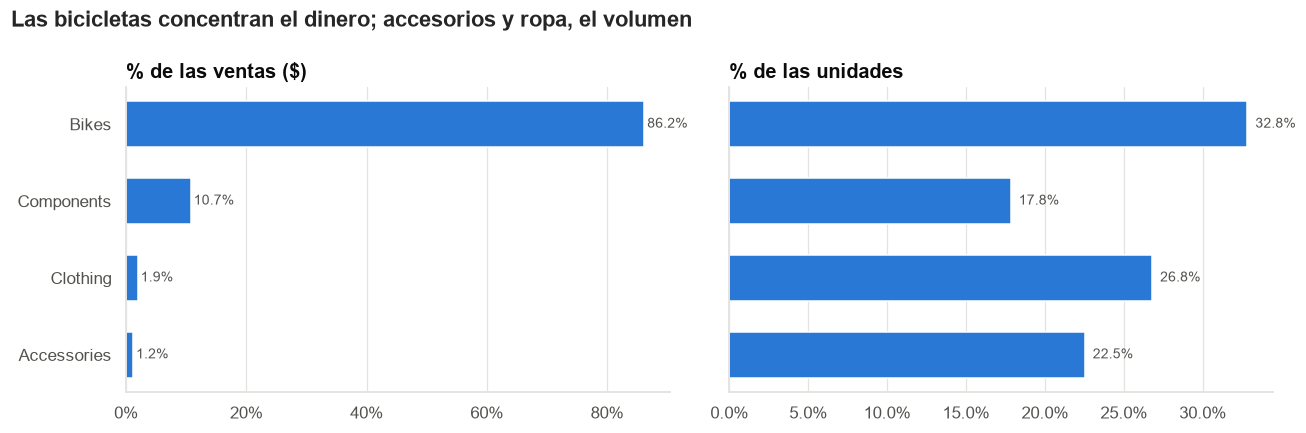

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
c = cat.sort_values("Ventas")
axes[0].barh(c.index, c["% ventas"], color=PALETTE[0], height=0.6)
axes[0].set_title("% de las ventas ($)")
axes[1].barh(c.index, c["% unidades"], color=PALETTE[0], height=0.6)
axes[1].set_title("% de las unidades")
for ax, col in zip(axes, ["% ventas", "% unidades"]):
    for y, v in enumerate(c[col]):
        ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=MUTED, fontsize=9)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
plt.suptitle("Las bicicletas concentran el dinero; accesorios y ropa, el volumen", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

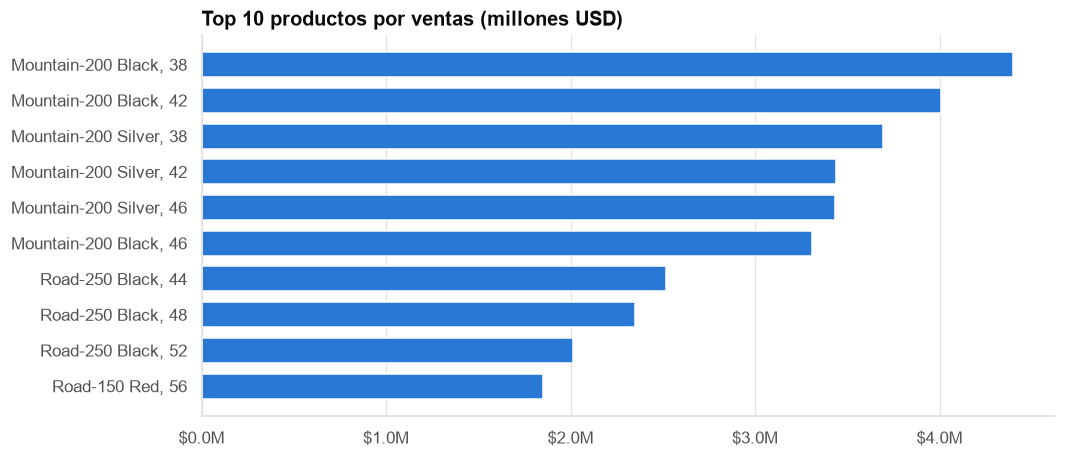

In [18]:
top = details.groupby(["Product", "Category"])["LineTotal"].sum().nlargest(10).reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top["Product"][::-1], top["LineTotal"][::-1] / 1e6, color=PALETTE[0], height=0.7)
ax.set_title("Top 10 productos por ventas (millones USD)")
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("$%.1fM")); ax.grid(axis="y", visible=False)
plt.show()

In [19]:
details["Margin"] = details["LineTotal"] - details["StandardCost"] * details["OrderQty"]
mg = details.groupby("Category")[["LineTotal", "Margin"]].sum()
mg["Margen %"] = 100 * mg["Margin"] / mg["LineTotal"]
mg.sort_values("Margen %", ascending=False)

,LineTotal,Margin,Margen %
Category,,,
Accessories,"1,272,072.88","636,394.26",50.03
Clothing,"2,120,542.52","308,882.17",14.57
Bikes,"94,651,172.70","7,936,394.02",8.38
Components,"11,802,593.29","490,233.18",4.15


> **Nota:** `StandardCost` es el costo estándar **actual** del producto, no el histórico; el margen es una aproximación.

## 8. Distribuciones: ticket y descuentos

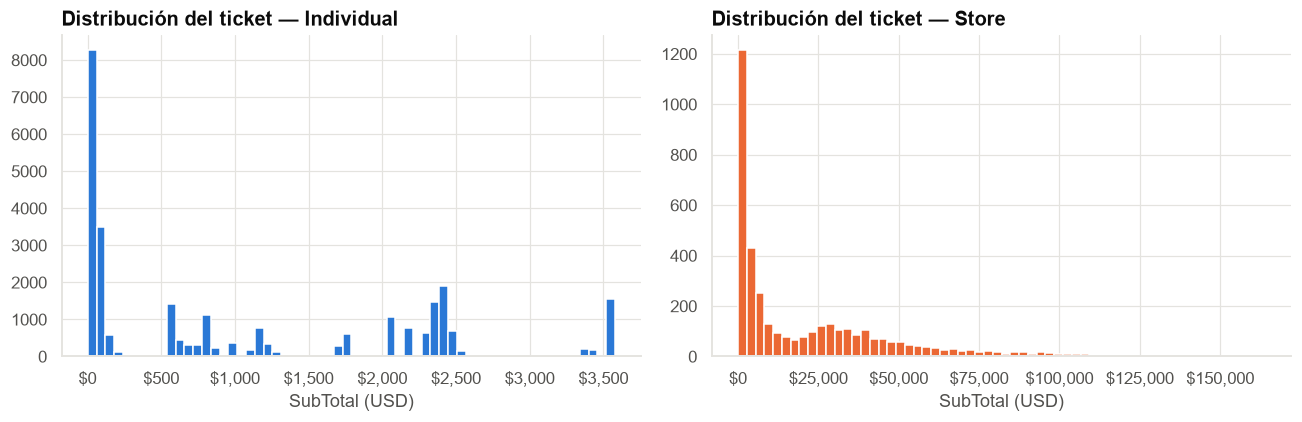

Asimetría (skewness) del ticket: {'Individual': 0.73, 'Store': 1.54}


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (ct, ax) in enumerate(zip(["Individual", "Store"], axes)):
    ax.hist(orders.loc[orders.CustomerType == ct, "SubTotal"], bins=60, color=PALETTE[i], log=False)
    ax.set_title(f"Distribución del ticket — {ct}"); ax.set_xlabel("SubTotal (USD)")
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout(); plt.show()
print("Asimetría (skewness) del ticket:", orders.groupby("CustomerType")["SubTotal"].skew().round(2).to_dict())

> Distribuciones **muy asimétricas a la derecha** → para K‑Means aplicaremos una transformación logarítmica.

In [21]:
disc = details.assign(ConDescuento=details.UnitPriceDiscount > 0)
print(f"Líneas con descuento: {disc.ConDescuento.mean():.1%}")
print(f"Descuento promedio (cuando hay): {details.loc[details.UnitPriceDiscount > 0, 'UnitPriceDiscount'].mean():.1%}")
disc.groupby("Category")["ConDescuento"].mean().mul(100).round(1).to_frame("% líneas con descuento")

Líneas con descuento: 2.7%
Descuento promedio (cuando hay): 10.4%


,% líneas con descuento
Category,
Accessories,1.40
Bikes,3.50
Clothing,5.70
Components,0.50


## 9. Motivos de compra (Sales Reasons)

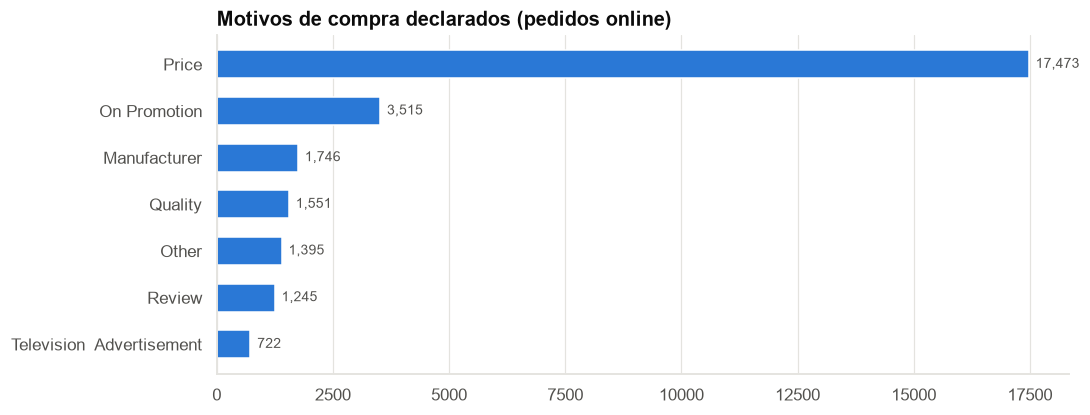

In [22]:
r = reasons.groupby(["Reason", "ReasonType"]).size().sort_values().rename("Pedidos").reset_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(r["Reason"], r["Pedidos"], color=PALETTE[0], height=0.6)
for y, v in enumerate(r["Pedidos"]):
    ax.text(v + 150, y, f"{v:,}", va="center", color=MUTED, fontsize=9)
ax.set_title("Motivos de compra declarados (pedidos online)"); ax.grid(axis="y", visible=False)
plt.show()

## 10. Perfil demográfico de clientes individuales

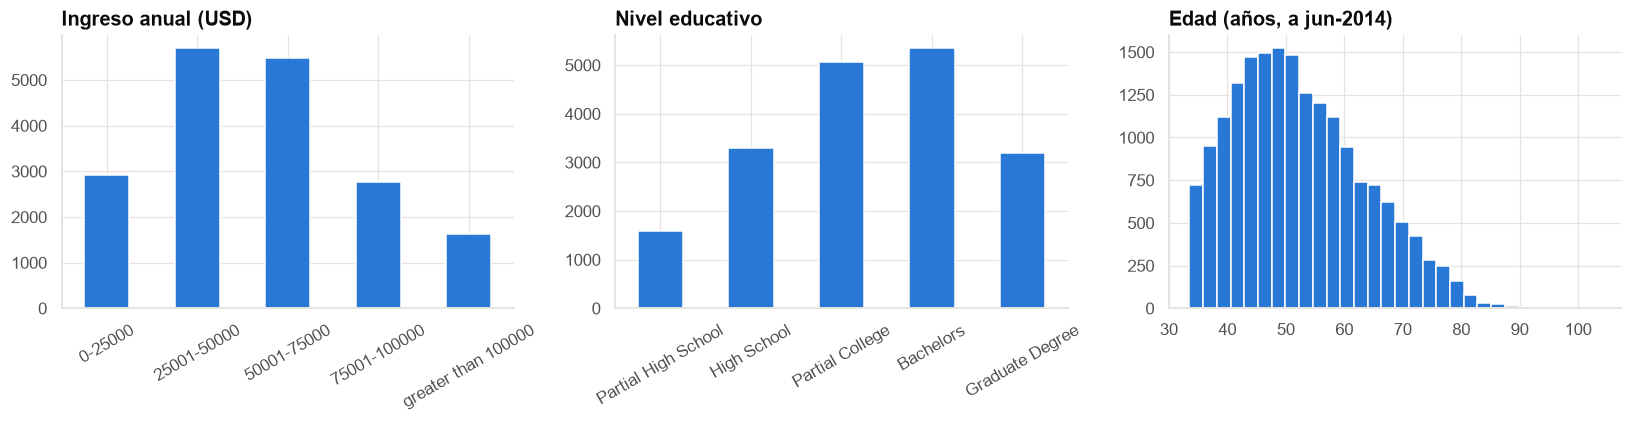

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
demo["YearlyIncome"].value_counts(sort=False).plot.bar(ax=axes[0], color=PALETTE[0], rot=30)
axes[0].set_title("Ingreso anual (USD)")
demo["Education"].value_counts(sort=False).plot.bar(ax=axes[1], color=PALETTE[0], rot=30)
axes[1].set_title("Nivel educativo")
age = ((orders.OrderDate.max() - demo["BirthDate"]).dt.days / 365.25)
axes[2].hist(age, bins=30, color=PALETTE[0]); axes[2].set_title("Edad (años, a jun-2014)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 11. Variables por cliente (base para el clustering)

Construimos una fila por cliente individual con **Recency, Frequency, Monetary** y variables de perfil.

In [24]:
feats = build_customer_features(orders, details, demo)
feats[["Recency", "Frequency", "Monetary", "AvgTicket", "Tenure", "Items", "Age"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,"18,484.00",190.33,146.29,1.00,87.00,169.00,264.00,"1,127.00"
Frequency,"18,484.00",1.50,1.10,1.00,1.00,1.00,2.00,28.00
Monetary,"18,484.00","1,588.33","2,124.23",2.29,49.97,270.26,"2,511.28","13,295.38"
AvgTicket,"18,484.00",911.86,"1,040.83",2.29,39.98,157.01,"1,770.45","3,578.27"
Tenure,"18,484.00",347.74,277.08,1.00,141.00,270.00,474.00,"1,127.00"
Items,"18,484.00",3.27,2.62,1.00,2.00,3.00,4.00,68.00
Age,"18,484.00",51.92,11.26,33.00,43.00,50.00,59.00,103.00


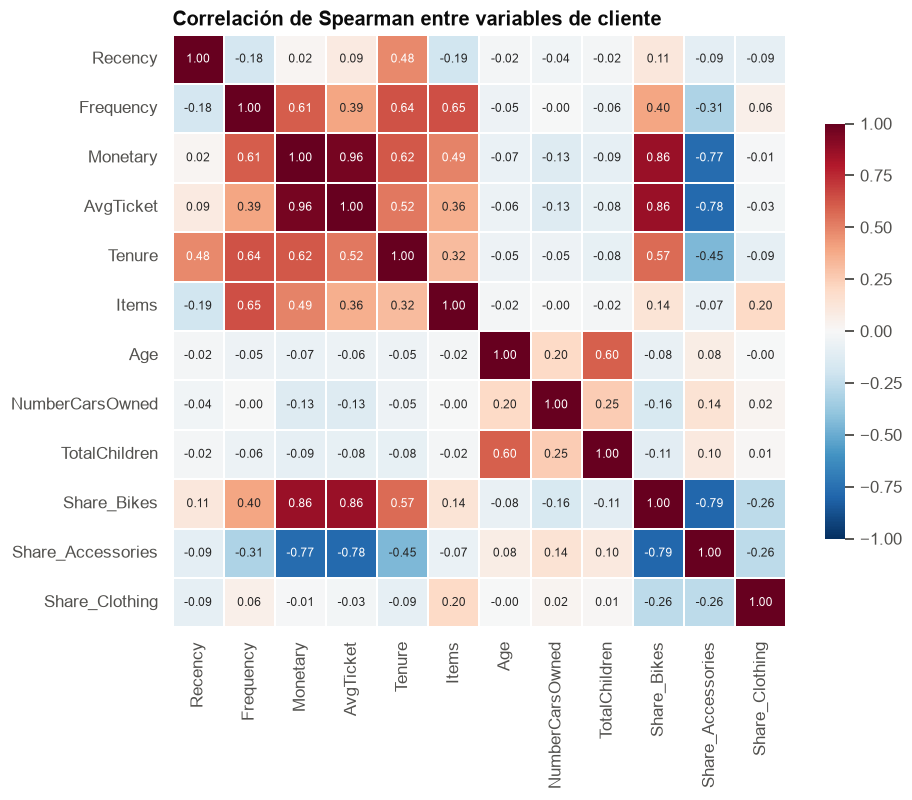

In [25]:
num = ["Recency", "Frequency", "Monetary", "AvgTicket", "Tenure", "Items", "Age", "NumberCarsOwned",
       "TotalChildren", "Share_Bikes", "Share_Accessories", "Share_Clothing"]
corr = feats[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor="white", ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlación de Spearman entre variables de cliente")
plt.show()

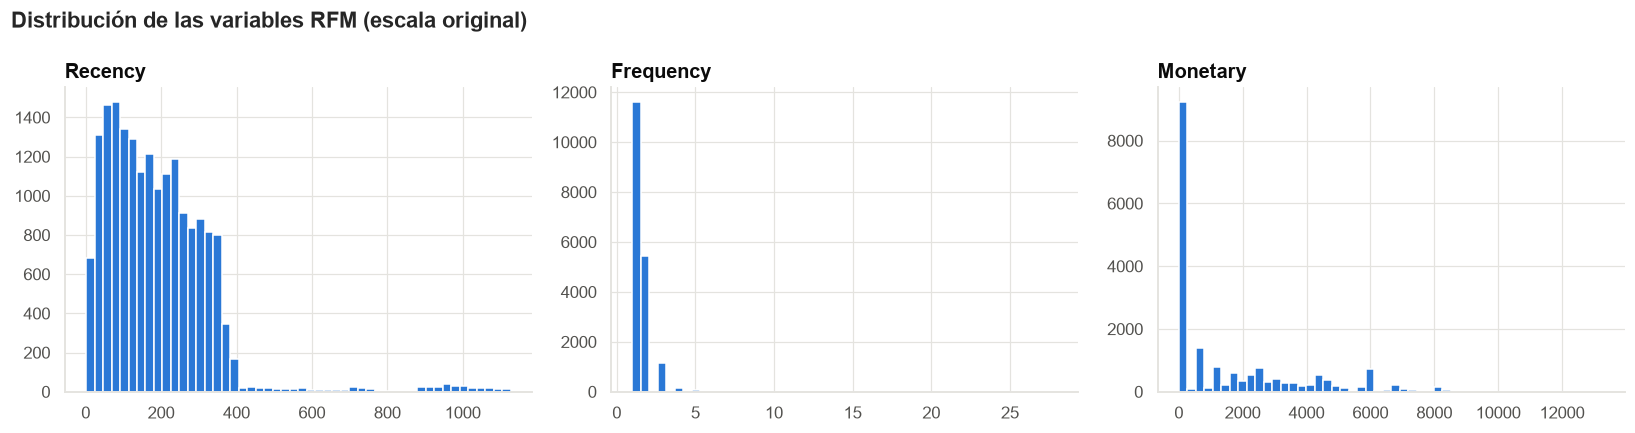

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(feats[col], bins=50, color=PALETTE[0]); ax.set_title(col)
plt.suptitle("Distribución de las variables RFM (escala original)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 12. Conclusiones del EDA

1. **Datos limpios:** sin duplicados, sin valores negativos y con consistencia contable total (`TotalDue = SubTotal + Tax + Freight` y `SubTotal = Σ LineTotal`). El único nulo relevante (`SalesPersonID`, 88 %) es estructural: los pedidos online no tienen vendedor.
2. **Periodo:** 31/05/2011 → 30/06/2014 (2011 y 2014 son años parciales). Ventas netas totales ≈ **$109,8 M** en 31.465 pedidos.
3. **Dos negocios distintos:** las **635 tiendas (B2B)** generan el **73 %** de las ventas con ticket medio ≈ $21.100; los **18.484 clientes individuales (B2C)** hacen el 88 % de los pedidos, pero con ticket ≈ $1.060.
4. **Bicicletas = dinero, accesorios/ropa = volumen:** Bikes aporta el 86 % de las ventas pero solo el 33 % de las unidades. Los accesorios tienen el mayor margen aproximado (~50 %).
5. **Cambio estructural en 2013‑T3:** explosión de pedidos online de bajo valor (accesorios y ropa).
6. **Distribuciones muy asimétricas** en Frequency (skew ≈ 12,6) y Monetary: hay que transformar (log) y escalar antes de K‑Means.
7. **Decisión de modelado:** segmentar **solo clientes individuales** con variables **RFM**, y usar demografía, territorio y mezcla de categorías solo para **describir** los clusters (no para entrenarlos).